#Trabajo Principal

**Análisis de señales a diferentes frecuencias**

Primero, vamos a crear un vector de tiempo discreto de 1 s con una frecuencia de muestreo de 100 Hz. Representaremos un seno a 10 Hz y, posteriormente, configuraremos un sistema dinámico para representar múltiples senos con un desfase de pi/3 radianes.

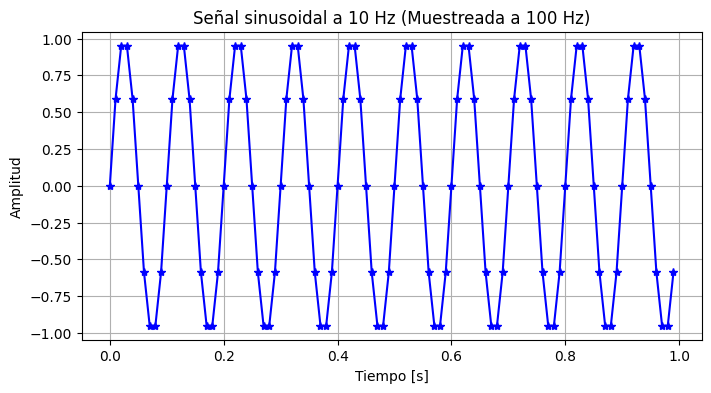

Introduce la frecuencia 5 en Hz: 90


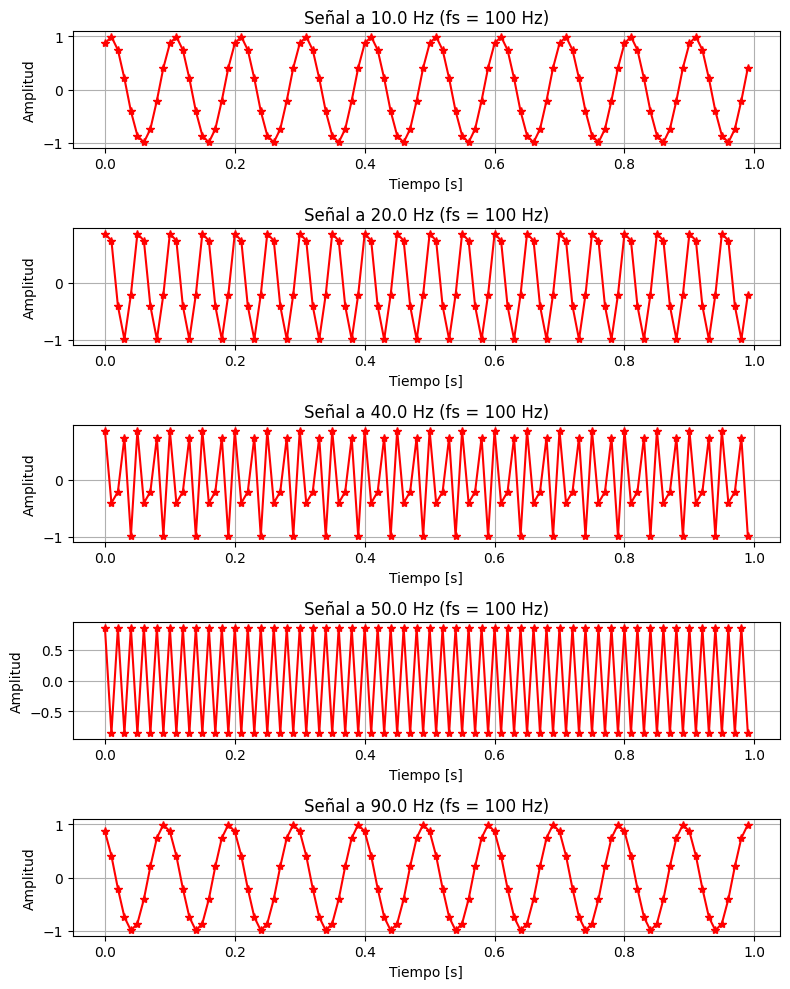

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Vector de tiempo discreto (1 s duración, fs = 100 Hz)
fs = 100 # Hz
tmax = 1 # s
ts = np.arange(0, tmax, 1/fs)

# 2 y 3. Señal a 10 Hz y su representación en una única figura
f1 = 10 # Hz
signal_10hz = np.sin(2 * np.pi * f1 * ts)

plt.figure(1, figsize=(8,4), dpi=100)
plt.plot(ts, signal_10hz, 'b*-')
plt.title('Señal sinusoidal a 10 Hz (Muestreada a 100 Hz)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

# 4. Señales dinámicas con desfase pi/3
cantidad = int(input("Introduce la cantidad de frecuencias a representar (ej. 5): "))
freqs = []
for i in range(cantidad):
    freq = float(input(f"Introduce la frecuencia {i+1} en Hz: "))
    freqs.append(freq)

# Creamos la figura con subgráficas
fig2, axs = plt.subplots(len(freqs), figsize=(8, 2*len(freqs)), dpi=100)
# Si solo hay 1 frecuencia, axs no es un array, así que lo forzamos para evitar errores
if len(freqs) == 1: axs = [axs]

for i in range(len(freqs)):
    fr = freqs[i]
    # Seno con desfase de pi/3
    signal_dinamica = np.sin(2 * np.pi * fr * ts + (np.pi/3))

    axs[i].plot(ts, signal_dinamica, 'r*-')
    axs[i].set_title(f'Señal a {fr} Hz (fs = 100 Hz)')
    axs[i].set_xlabel('Tiempo [s]')
    axs[i].set_ylabel('Amplitud')
    axs[i].grid(True)

fig2.tight_layout()
plt.show()

**¿Son lógicos estos resultados?**

Sí, desde el punto de vista matemático y del Teorema de Nyquist-Shannon, los resultados son totalmente lógicos.

**¿Qué está pasando con el seno a 90 Hz?**

Con el seno de 90 Hz está ocurriendo el fenómeno de aliasing.

**¿Por qué los otros no tienen ese problema?**

Los otros senos (10, 20, 40 Hz) no tienen este problema porque su frecuencia es inferior a la mitad de la frecuencia de muestreo ($f_{max} < f_s / 2$). Como $f_s = 100$ Hz, el límite de Nyquist es 50 Hz.

**¿Se parece a alguna otra señal?**

El seno de 90 Hz se parece sospechosamente a un seno de 10 Hz. Al no cumplir el criterio de muestreo, la frecuencia "se pliega" o "rebota" y el sistema la interpreta erróneamente como una frecuencia más baja (100 Hz - 90 Hz = 10 Hz).

**¿Riesgo de confundirlas?**

Sí, hay un riesgo total de confundirlas. Si solo viéramos los puntos de la señal muestreada a 90 Hz, juraríamos que es una señal de 10 Hz.  



**¿Cómo se podría evitar esto?**


Se podría evitar aumentando la frecuencia de muestreo para que sea estrictamente superior a 180 Hz ($f_s > 2 \cdot 90$ Hz). En un entorno real, también se evitaría colocando un filtro paso bajo analógico (filtro anti-aliasing) antes de digitalizar la señal.

**Representación del Aliasing entre -1 Hz y 9 Hz**

Vamos a comparar cómo se ven dos señales continuas de frecuencias muy distintas (-1 Hz y 9 Hz) cuando son sometidas a una frecuencia de muestreo insuficiente de 10 Hz.

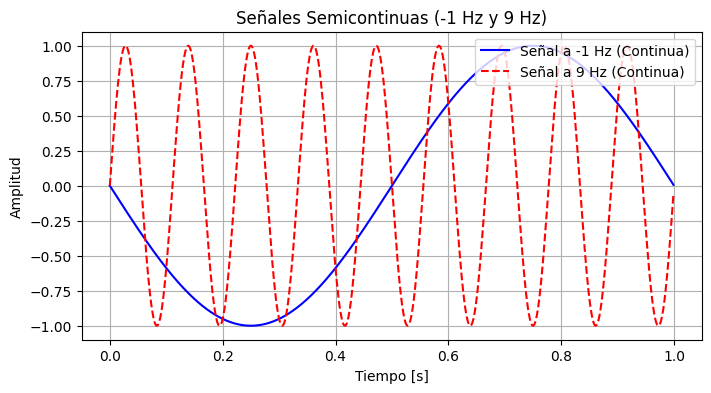

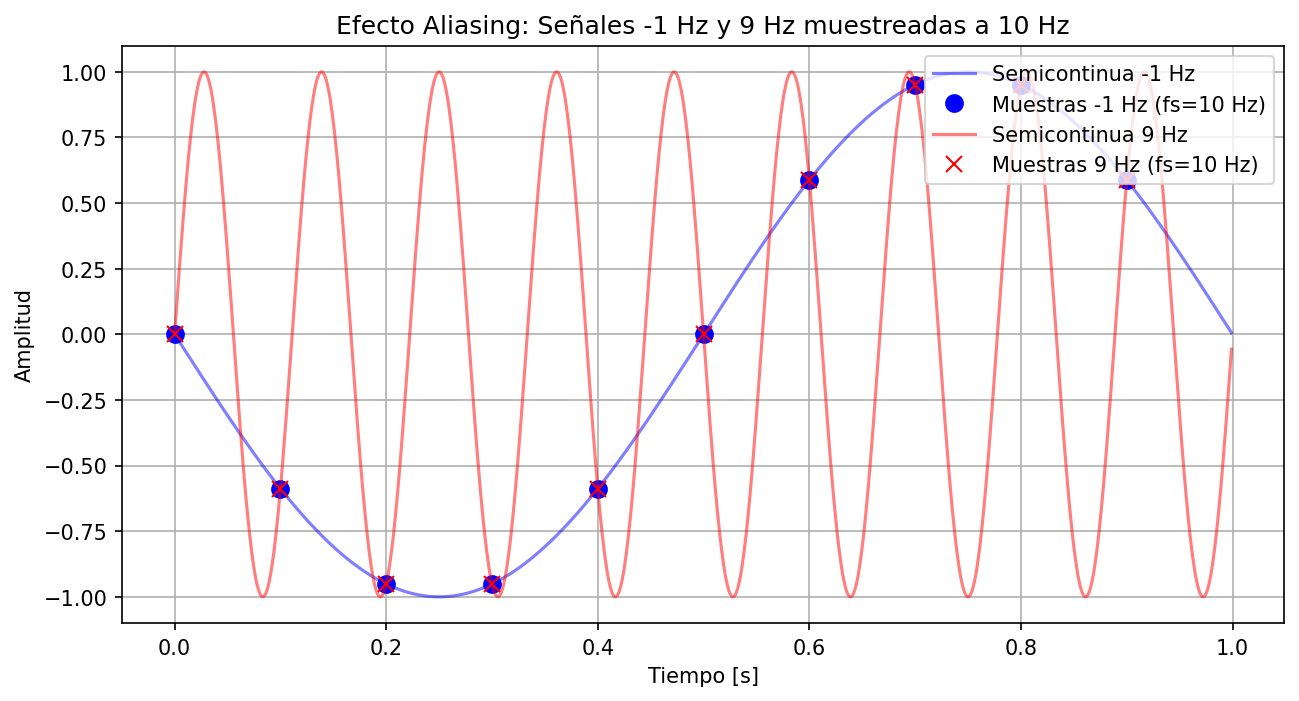

In [3]:
# Vector de tiempo semicontinuo a 1000 Hz
t_semi = np.arange(0, 1, 0.001)

# Señales a -1 Hz y 9 Hz en tiempo semicontinuo
sig_semi_minus1 = np.sin(2 * np.pi * (-1) * t_semi)
sig_semi_9 = np.sin(2 * np.pi * 9 * t_semi)

# Representación de las semicontinuas
plt.figure(3, figsize=(8,4), dpi=100)
plt.plot(t_semi, sig_semi_minus1, 'b-', label='Señal a -1 Hz (Continua)')
plt.plot(t_semi, sig_semi_9, 'r--', label='Señal a 9 Hz (Continua)')
plt.title('Señales Semicontinuas (-1 Hz y 9 Hz)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

# Vectores muestreados (fs = 10 Hz)
fs_low = 10
ts_low = np.arange(0, 1, 1/fs_low)

sig_samp_minus1 = np.sin(2 * np.pi * (-1) * ts_low)
sig_samp_9 = np.sin(2 * np.pi * 9 * ts_low)

# Representación de continuas + muestreadas
plt.figure(4, figsize=(10,5), dpi=150)
plt.plot(t_semi, sig_semi_minus1, 'b-', alpha=0.5, label='Semicontinua -1 Hz')
plt.plot(ts_low, sig_samp_minus1, 'bo', markersize=8, label='Muestras -1 Hz (fs=10 Hz)')

plt.plot(t_semi, sig_semi_9, 'r-', alpha=0.5, label='Semicontinua 9 Hz')
plt.plot(ts_low, sig_samp_9, 'rx', markersize=8, label='Muestras 9 Hz (fs=10 Hz)')

plt.title('Efecto Aliasing: Señales -1 Hz y 9 Hz muestreadas a 10 Hz')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

**¿Sería posible diferenciar ambas señales si solo tenemos las muestras?**

No, sería absolutamente imposible. Si observamos la última gráfica generada, los puntos rojos de la señal de 9 Hz coinciden exactamente en las mismas coordenadas espaciales que los puntos azules de la señal de -1 Hz.  

**¿Por qué ocurre esto? ¿Qué debería haberse cumplido?**

Ocurre debido al aliasing. Al muestrear una señal de 9 Hz a una velocidad de 10 Hz, la frecuencia aparente resultante es $9 - 10 = -1$ Hz. Para que esto no ocurriera, se debería haber cumplido el criterio de Nyquist: la frecuencia de muestreo tendría que haber sido estrictamente mayor que el doble de la frecuencia máxima de la señal ($f_s > 18$ Hz).

#Trabajo Opcional

**Interpolación de señales con y sin Aliasing**

A continuación, reducimos la ventana temporal a 0.1 s y tratamos de reconstruir matemáticamente las señales de 20 Hz y 90 Hz muestreadas a 100 Hz.

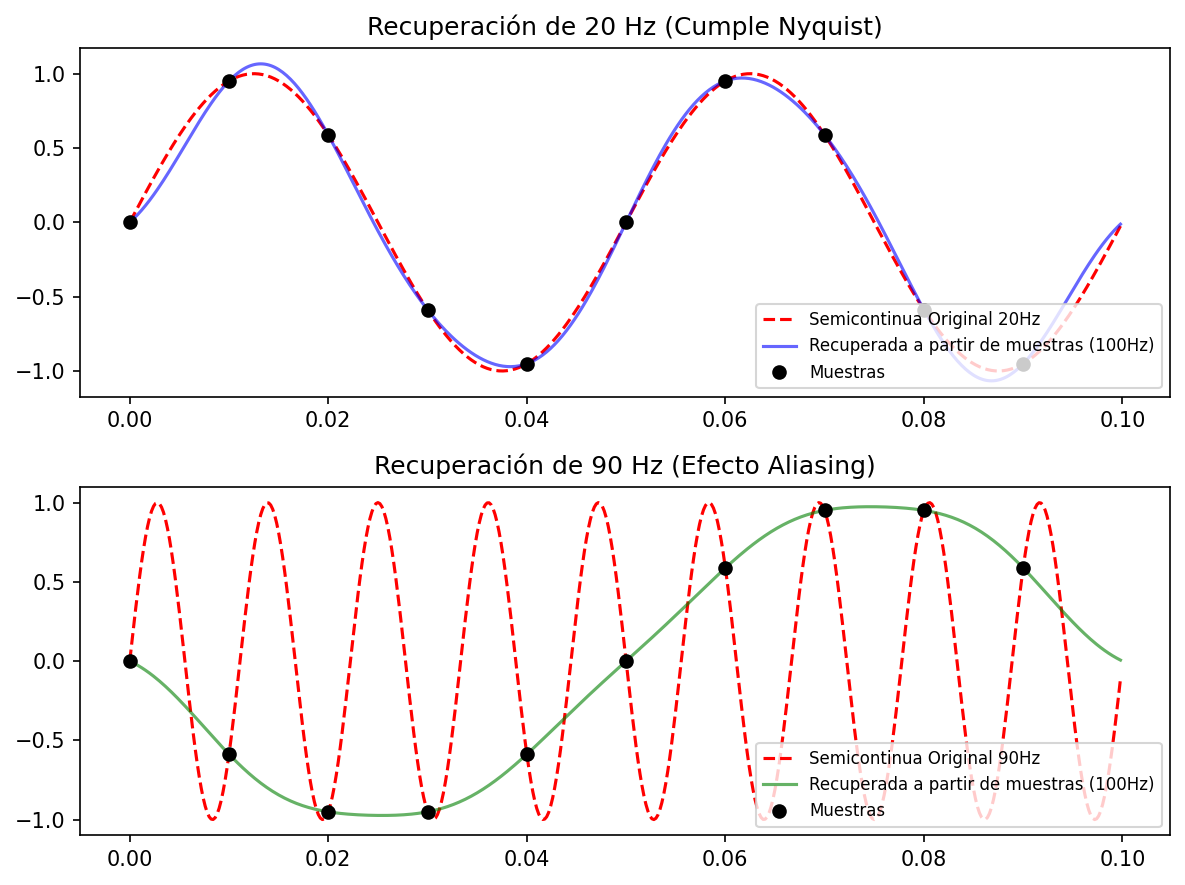

In [4]:
# Definición de tiempos (0.1s de duración)
t_opt_semi = np.arange(0, 0.1, 1/5000)
t_opt_samp = np.arange(0, 0.1, 1/100)

# Señales a 20 Hz (Cumple Nyquist) y 90 Hz (No cumple Nyquist)
sig20_semi = np.sin(2 * np.pi * 20 * t_opt_semi)
sig20_samp = np.sin(2 * np.pi * 20 * t_opt_samp)

sig90_semi = np.sin(2 * np.pi * 90 * t_opt_semi)
sig90_samp = np.sin(2 * np.pi * 90 * t_opt_samp)

# Función para reconstruir aplicando Whittaker-Shannon con corrección del límite x=0
def reconstruir_ws(t_cont, t_disc, sig_disc, fs_disc):
    sig_rec = np.zeros(len(t_cont))
    for i in range(len(t_cont)):
        for j in range(len(t_disc)):
            x = fs_disc * t_cont[i] - j
            sinc_val = 1.0 if x == 0 else np.sin(np.pi * x) / (np.pi * x)
            sig_rec[i] += sig_disc[j] * sinc_val
    return sig_rec

# Reconstruimos
sig20_rec = reconstruir_ws(t_opt_semi, t_opt_samp, sig20_samp, 100)
sig90_rec = reconstruir_ws(t_opt_semi, t_opt_samp, sig90_samp, 100)

# Representación
fig_opt, axs_opt = plt.subplots(2, figsize=(8,6), dpi=150)

# Gráfica para 20 Hz
axs_opt[0].plot(t_opt_semi, sig20_semi, 'r--', label='Semicontinua Original 20Hz')
axs_opt[0].plot(t_opt_semi, sig20_rec, 'b-', alpha=0.6, label='Recuperada a partir de muestras (100Hz)')
axs_opt[0].plot(t_opt_samp, sig20_samp, 'ko', label='Muestras')
axs_opt[0].set_title('Recuperación de 20 Hz (Cumple Nyquist)')
axs_opt[0].legend(loc='lower right', fontsize=8)

# Gráfica para 90 Hz
axs_opt[1].plot(t_opt_semi, sig90_semi, 'r--', label='Semicontinua Original 90Hz')
axs_opt[1].plot(t_opt_semi, sig90_rec, 'g-', alpha=0.6, label='Recuperada a partir de muestras (100Hz)')
axs_opt[1].plot(t_opt_samp, sig90_samp, 'ko', label='Muestras')
axs_opt[1].set_title('Recuperación de 90 Hz (Efecto Aliasing)')
axs_opt[1].legend(loc='lower right', fontsize=8)

fig_opt.tight_layout()
plt.show()

**¿Qué observas? ¿Es lógico lo que ocurre?**

Observo que la señal de 20 Hz se reconstruye a la perfección: la curva azul recuperada coincide exactamente con la roja original. Sin embargo, al aplicar la fórmula a las muestras de la señal de 90 Hz, obtenemos una curva verde a baja frecuencia (10 Hz) que no se parece en nada a la señal roja de alta frecuencia.  

Es completamente lógico. Las matemáticas de interpolación de Whittaker-Shannon funcionan sobre las muestras discretas aportadas, asumiendo que no hay componentes espectrales superiores a $f_s / 2$. Al darle muestras "viciadas" de aliasing, la fórmula asume y reconstruye con naturalidad una onda lenta que encaje por esos puntos, confirmando la destrucción irreversible de la información original.